# Project 1 – Natural Language Inference (SNLI)

**Task:** given a *premise* and a *hypothesis*, predict whether the premise **entails**, **contradicts** or is **neutral** towards the hypothesis.

**What we compare:**

| | |
|---|---|
| **Representations** | R1 token indicators · R2 bag-of-words · R3 bag-of-words + cross-sentence features |
| **Architectures** | A1 log-linear · A2 MLP (tutorial) · A3 MLP with more regularisation |
| **Evaluation** | 5-fold cross-validation, accuracy, Bayesian estimation with a ROPE |


## 0. Setup

In [35]:
import re
import sys
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.simplefilter("ignore")

# the course code (part1/) is in the same folder as this notebook
sys.path.insert(0, ".")
import part1

# the three labels, in the same order as SNLI uses them (0, 1, 2)
LABELS = part1.clslib.NamedClasses(["entailment", "neutral", "contradiction"])

SEED = 0

## 1. Data

We use SNLI. Pairs with label −1 are removed: those are pairs where the annotators did not agree on a label.

To keep the experiments fast we take a random **sample of 20,000 training pairs**. Every example is stored as `((premise, hypothesis), label)`.
- `train_pairs`: used for the tokenizer and cross-validation
- `val_pairs`: 2,000 pairs from SNLI's validation split, only used to look at how the MLP trains (section 6)
- `test_pairs`: SNLI's test split, used **once** at the very end

In [36]:
snli = load_dataset("stanfordnlp/snli")
print(snli)


def to_pairs(split):
    # turn a SNLI split into a list of ((premise, hypothesis), label)
    pairs = []
    for premise, hypothesis, label in zip(split["premise"], split["hypothesis"], split["label"]):
        if label != -1:   # -1 means the annotators did not agree, so we skip it
            pairs.append(((premise, hypothesis), label))
    return pairs


all_train = to_pairs(snli["train"])
all_val = to_pairs(snli["validation"])
test_pairs = to_pairs(snli["test"])

# take a random sample (with the same seed we get the same sample every time)
rng = np.random.default_rng(SEED)

train_order = rng.permutation(len(all_train))
train_pairs = []
for i in train_order[:50000]:
    train_pairs.append(all_train[i])

val_order = rng.permutation(len(all_val))
val_pairs = []
for i in val_order[:2000]:
    val_pairs.append(all_val[i])

print("train:", len(train_pairs), "| val:", len(val_pairs), "| test:", len(test_pairs))

# count how many pairs with label -1 were removed from each split
for split_name in ["train", "validation", "test"]:
    removed = 0
    for label in snli[split_name]["label"]:
        if label == -1:
            removed += 1
    print("removed (label -1) in the full", split_name, "split:", removed)

print("example:", train_pairs[0])

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})
train: 50000 | val: 2000 | test: 9824
removed (label -1) in the full train split: 785
removed (label -1) in the full validation split: 158
removed (label -1) in the full test split: 176
example: (('A man holding a video camera standing next to a woman by water.', 'The man is holding a microphone as he introduces the woman standing by the water.'), 2)


To find out whether we can use **accuracy** as an evaluation metric, we have to check whether the classes are balanced. If one class were much bigger, a model could get a high accuracy by mostly predicting that class.

entailment 16738 -> 0.335
neutral 16458 -> 0.329
contradiction 16804 -> 0.336


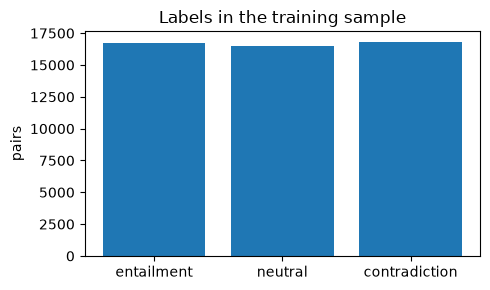

majority baseline: 0.336


In [37]:
label_counts = Counter()
for pair, label in train_pairs:
    label_counts[LABELS.name(label)] += 1

for name in LABELS:
    print(name, label_counts[name], "->", round(label_counts[name] / len(train_pairs), 3))

plt.figure(figsize=(5, 3))
plt.bar(list(LABELS), [label_counts[name] for name in LABELS])
plt.title("Labels in the training sample")
plt.ylabel("pairs")
plt.tight_layout()
plt.show()

# majority baseline: the accuracy you get by always predicting the biggest class
majority = max(label_counts.values()) / len(train_pairs)
print("majority baseline:", round(majority, 3))

Some quick statistics that motivate the features in R3 (section 5): how long are premises and hypotheses, and how often does the hypothesis contain a negation, per label?

In [38]:
# a regular expression that finds negation words like "not", "no", "nobody", "isn't"
NEGATION = re.compile(r"\b(?:not|no|never|nobody|nothing|none|cannot)\b|n't", re.IGNORECASE)


def has_negation(sentence):
    if NEGATION.search(sentence):
        return True
    else:
        return False


rows = []
for (premise, hypothesis), label in train_pairs:
    rows.append({
        "label": LABELS.name(label),
        "premise words": len(premise.split()),
        "hypothesis words": len(hypothesis.split()),
        "negation in hypothesis": has_negation(hypothesis),
    })
stats = pd.DataFrame(rows)

# average per label
stats.groupby("label").mean().loc[list(LABELS)].round(3)

,premise words,hypothesis words,negation in hypothesis
label,,,
entailment,12.894,6.644,0.008
neutral,12.805,8.261,0.009
contradiction,12.846,7.353,0.049


## 2. Tokenizer

As in the tutorial: a BPE tokenizer with `vocab_size=1000` and `min_frequency=2`, trained with the course's `train_tokenizer`. We train it on the premises and hypotheses of the **training pairs only**, so it never sees the test data.

In [39]:
corpus = []
for (premise, hypothesis), label in train_pairs:
    corpus.append(premise)
    corpus.append(hypothesis)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size=1000, min_frequency=2)

# look at one example
premise = train_pairs[0][0][0]
hypothesis = train_pairs[0][0][1]
print("premise:   ", tokenizer.encode(premise).tokens)
print("hypothesis:", tokenizer.encode(hypothesis).tokens)




premise:    ['▁A', '▁man', '▁holding', '▁a', '▁v', 'ide', 'o', '▁camera', '▁standing', '▁next', '▁to', '▁a', '▁woman', '▁by', '▁water.']
hypothesis: ['▁The', '▁man', '▁is', '▁holding', '▁a', '▁microph', 'one', '▁as', '▁he', '▁in', 't', 'ro', 'd', 'u', 'c', 'es', '▁the', '▁woman', '▁standing', '▁by', '▁the', '▁water.']


In [40]:
# a larger resource of the same kind: ALL premises and hypotheses of SNLI's training split
# (we only use the text, not the labels, and no test data, so this is allowed)
full_corpus = []
seen_premises = set()
for premise in snli["train"]["premise"]:
    if premise not in seen_premises:      # every premise appears ~3 times, keep it once
        seen_premises.add(premise)
        full_corpus.append(premise)
for hypothesis in snli["train"]["hypothesis"]:
    full_corpus.append(hypothesis)

print("sentences in our 20k corpus:", len(corpus))
print("sentences in the full corpus:", len(full_corpus))

# we test on the validation sentences, which neither tokenizer has seen
val_sentences = []
for (premise, hypothesis), label in val_pairs:
    val_sentences.append(premise)
    val_sentences.append(hypothesis)

rows = []
for corpus_name, training_text in [("20k sample", corpus), ("full SNLI train", full_corpus)]:
    for vocab_size in [500, 1000, 2000]:
        tok = part1.experiment.train_tokenizer(training_text, vocab_size=vocab_size, min_frequency=2)
        unk_id = tok.token_to_id("[UNK]")

        total_tokens = 0
        unknown_tokens = 0
        for sentence in val_sentences:
            ids = tok.encode(sentence).ids
            total_tokens += len(ids)
            for i in ids:
                if i == unk_id:
                    unknown_tokens += 1

        rows.append({
            "trained on": corpus_name,
            "vocab size": vocab_size,
            "tokens per sentence": round(total_tokens / len(val_sentences), 2),
            "UNK rate": round(unknown_tokens / total_tokens, 5),
        })

tokenizer_comparison = pd.DataFrame(rows)
tokenizer_comparison

sentences in our 20k corpus: 100000
sentences in the full corpus: 700888




















,trained on,vocab size,tokens per sentence,UNK rate
0,20k sample,500,20.09,0.0
1,20k sample,1000,16.39,0.0
2,20k sample,2000,14.05,0.0
3,full SNLI train,500,20.28,0.0
4,full SNLI train,1000,16.50,0.0
5,full SNLI train,2000,14.08,0.0


## 3. Representations R1 and R2

The tutorial's encoders turn **one** text into a vector. NLI has **two** texts, and it matters which sentence a word is in ("not" in the hypothesis means something different from "not" in the premise). So we make a vector for the premise and a vector for the hypothesis **separately** and put them next to each other:

`[ premise vector (V numbers) | hypothesis vector (V numbers) ]` → 2V numbers, with V = 1000.

- **R1 – token indicators:** 1 if a token is in the sentence, 0 if not.
- **R2 – bag-of-words:** how many times each token is in the sentence.

The only difference in the code is `= 1` (R1) versus `+= 1` (R2).

In [41]:
class PairIndicator:
    # R1: for premise and hypothesis, 1 if a token is in the sentence, 0 if not

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] = 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] = 1

        # put them next to each other
        return np.concatenate([premise_vector, hypothesis_vector])


class PairBagOfWords:
    # R2: same as R1 but we count how many times each token occurs

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        return np.concatenate([premise_vector, hypothesis_vector])

In [42]:
R1 = PairIndicator(tokenizer)
R2 = PairBagOfWords(tokenizer)

# test on an example
x = ("A man is playing a guitar on a stage.", "A man is not playing music.")
print("dimensions:", len(R1), len(R2))
print("sum of R1:", R1(x).sum(), "| sum of R2:", R2(x).sum())   # R2 is bigger because "a" is counted twice

dimensions: 2000 2000
sum of R1: 16.0 | sum of R2: 17.0


## 4. Cross-validation with A1 and A2

We use the course's `cross_validation_split` (5 folds) and `cross_validation_experiment`. The architectures are just settings for that function:

- **A1** – log-linear softmax regression (scikit-learn), as in the tutorial
- **A2** – one-hidden-layer MLP with the tutorial's settings

`run(name, encoder, architecture)` does the cross-validation for one system and stores the results in `my_classifiers`, in the same format as the tutorial, so the course's analysis functions work on it.

`my_seeds = [0]` gives 5 accuracies per system (one per fold).

In [43]:
A1 = {
    "model_option": "logistic",
    "loglin_args": {"max_iter": 100},
    "smlp_args": {},
}

A2 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 10},
}

num_folds = 5
my_seeds = [0]

# make the folds once, so every system uses exactly the same folds
cv_sets = {}
for seed in my_seeds:
    cv_sets[seed] = part1.experiment.cross_validation_split(train_pairs, k=num_folds, seed=seed)

my_classifiers = {}


def run(name, encoder, architecture):
    # cross-validate one system and save the results under `name`
    my_classifiers[name] = []
    all_accuracies = []

    for seed in my_seeds:
        result = part1.experiment.cross_validation_experiment(
            data_splits=cv_sets[seed],
            outcome_space=LABELS,
            encoder=encoder,
            model_option=architecture["model_option"],
            loglin_args=architecture["loglin_args"],
            smlp_args=architecture["smlp_args"],
            save_to="results/" + name + "/seed-" + str(seed),
        )
        my_classifiers[name].append(result)

        for accuracy in result["accuracies"].values():
            all_accuracies.append(accuracy)

    print(name, "mean accuracy:", round(np.mean(all_accuracies), 4), "(std", round(np.std(all_accuracies), 4), ")")

In [44]:
run("A1_R1", R1, A1)
run("A1_R2", R2, A1)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R1 mean accuracy: 0.5832 (std 0.0073 )


  0%|          | 0/5 [00:00<?, ?it/s]

A1_R2 mean accuracy: 0.582 (std 0.0065 )


In [45]:
run("A2_R1", R1, A2)
run("A2_R2", R2, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.895 seconds
Dataloader done! Time taken: 0.563 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0729 | train acc: 0.4425 | val loss: 1.0352 | val acc: 0.5164
Epoch 02 | train loss: 0.9842 | train acc: 0.5514 | val loss: 0.9647 | val acc: 0.5477
Epoch 03 | train loss: 0.9204 | train acc: 0.5826 | val loss: 0.9328 | val acc: 0.5657
Epoch 04 | train loss: 0.8845 | train acc: 0.5995 | val loss: 0.9179 | val acc: 0.5733
Epoch 05 | train loss: 0.8603 | train acc: 0.6140 | val loss: 0.9102 | val acc: 0.5779
Epoch 06 | train loss: 0.8447 | train acc: 0.6215 | val loss: 0.9057 | val acc: 0.5821
Epoch 07 | train loss: 0.8302 | train acc: 0.6311 | val loss: 0.9039 | val acc: 0.5838
Epoch 08 | train loss: 0.8194 | train acc: 0.6356 | val loss: 0.9025 | val acc: 0.5845
Epoch 09 | train loss: 0.8077 | train acc: 0.6442 | val loss: 0.9009 | val acc: 0.5840
Epoch 10 | train loss: 0.7982 | train acc: 0.6483 | val loss: 0.9002 | val acc: 0.5871
Training done! Time taken: 22.268 seconds
Transforming documents...
Document transformation done! Time taken: 1.893 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0704 | train acc: 0.4480 | val loss: 1.0352 | val acc: 0.5096
Epoch 02 | train loss: 0.9810 | train acc: 0.5531 | val loss: 0.9713 | val acc: 0.5419
Epoch 03 | train loss: 0.9174 | train acc: 0.5856 | val loss: 0.9453 | val acc: 0.5549
Epoch 04 | train loss: 0.8815 | train acc: 0.6045 | val loss: 0.9320 | val acc: 0.5632
Epoch 05 | train loss: 0.8585 | train acc: 0.6157 | val loss: 0.9251 | val acc: 0.5653
Epoch 06 | train loss: 0.8421 | train acc: 0.6249 | val loss: 0.9212 | val acc: 0.5700
Epoch 07 | train loss: 0.8283 | train acc: 0.6324 | val loss: 0.9191 | val acc: 0.5700
Epoch 08 | train loss: 0.8163 | train acc: 0.6383 | val loss: 0.9185 | val acc: 0.5700
Epoch 09 | train loss: 0.8064 | train acc: 0.6453 | val loss: 0.9178 | val acc: 0.5714
Epoch 10 | train loss: 0.7964 | train acc: 0.6514 | val loss: 0.9175 | val acc: 0.5727
Training done! Time taken: 23.253 seconds
Transforming documents...
Document transformation done! Time taken: 2.088 seconds
Datalo

... (14 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0720 | train acc: 0.4445 | val loss: 1.0324 | val acc: 0.5200
Epoch 02 | train loss: 0.9909 | train acc: 0.5438 | val loss: 0.9628 | val acc: 0.5619
Epoch 03 | train loss: 0.9296 | train acc: 0.5788 | val loss: 0.9267 | val acc: 0.5762
Epoch 04 | train loss: 0.8933 | train acc: 0.5983 | val loss: 0.9079 | val acc: 0.5839
Epoch 05 | train loss: 0.8675 | train acc: 0.6111 | val loss: 0.9000 | val acc: 0.5844
Epoch 06 | train loss: 0.8494 | train acc: 0.6210 | val loss: 0.8930 | val acc: 0.5892
Epoch 07 | train loss: 0.8353 | train acc: 0.6277 | val loss: 0.8886 | val acc: 0.5921
Epoch 08 | train loss: 0.8224 | train acc: 0.6350 | val loss: 0.8878 | val acc: 0.5902
Epoch 09 | train loss: 0.8106 | train acc: 0.6402 | val loss: 0.8847 | val acc: 0.5927
Epoch 10 | train loss: 0.7992 | train acc: 0.6485 | val loss: 0.8837 | val acc: 0.5937
Training done! Time taken: 22.554 seconds
Transforming documents...
Document transformation done! Time taken: 2.130 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0709 | train acc: 0.4555 | val loss: 1.0333 | val acc: 0.5219
Epoch 02 | train loss: 0.9858 | train acc: 0.5540 | val loss: 0.9655 | val acc: 0.5531
Epoch 03 | train loss: 0.9220 | train acc: 0.5831 | val loss: 0.9353 | val acc: 0.5634
Epoch 04 | train loss: 0.8855 | train acc: 0.6041 | val loss: 0.9196 | val acc: 0.5749
Epoch 05 | train loss: 0.8612 | train acc: 0.6157 | val loss: 0.9124 | val acc: 0.5767
Epoch 06 | train loss: 0.8446 | train acc: 0.6237 | val loss: 0.9091 | val acc: 0.5770
Epoch 07 | train loss: 0.8313 | train acc: 0.6315 | val loss: 0.9056 | val acc: 0.5806
Epoch 08 | train loss: 0.8189 | train acc: 0.6374 | val loss: 0.9031 | val acc: 0.5847
Epoch 09 | train loss: 0.8075 | train acc: 0.6453 | val loss: 0.9021 | val acc: 0.5839
Epoch 10 | train loss: 0.7976 | train acc: 0.6500 | val loss: 0.9025 | val acc: 0.5830
Training done! Time taken: 22.701 seconds
A2_R2 mean accuracy: 0.5864 (std 0.0068 )


## 5. Representation R3: cross-sentence features

R1 and R2 describe each sentence on its own. But NLI is about **how the two sentences relate**, and a log-linear model cannot work that out from two separate halves of a vector. R3 adds features that describe the relation directly:

| Feature | Idea |
|---|---|
| **new tokens in H** (V numbers) | tokens in the hypothesis that are not in the premise → new information suggests *neutral* |
| **overlap** | share of hypothesis tokens that also occur in the premise → high overlap suggests *entailment* |
| **length difference** | (len H − len P) / (len H + len P) |
| **negation** | hypothesis has a negation word and the premise does not → suggests *contradiction* |

R3 = R2 + these features → 3V + 3 numbers. All extra features are between −1 and 1, on the same scale as the other features.

In [46]:
class PairCrossFeatures:
    # R3: R2 + features that compare the premise and the hypothesis

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part + new-tokens part + 3 extra numbers
        return self.vocab_size * 3 + 3

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        # part 1 and 2: bag-of-words, the same as R2
        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        # part 3: tokens that are in the hypothesis but NOT in the premise
        new_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            if i not in premise_ids:
                new_vector[i] = 1

        # overlap: which part of the hypothesis tokens also appears in the premise
        if len(hypothesis_ids) > 0:
            in_premise = 0
            for i in hypothesis_ids:
                if i in premise_ids:
                    in_premise += 1
            overlap = in_premise / len(hypothesis_ids)
        else:
            overlap = 0

        # length difference, scaled to be between -1 and 1
        total_length = len(hypothesis_ids) + len(premise_ids)
        if total_length > 0:
            length_difference = (len(hypothesis_ids) - len(premise_ids)) / total_length
        else:
            length_difference = 0

        # negation: 1 if the hypothesis has a negation word and the premise doesn't
        if has_negation(hypothesis) and not has_negation(premise):
            negation = 1
        else:
            negation = 0

        extra = np.array([overlap, length_difference, negation])
        return np.concatenate([premise_vector, hypothesis_vector, new_vector, extra])


R3 = PairCrossFeatures(tokenizer)
print("dimensions:", len(R3))
print("overlap, length difference, negation for the example:", R3(x)[-3:])

dimensions: 3003
overlap, length difference, negation for the example: [ 0.57142857 -0.17647059  1.        ]


In [47]:
run("A1_R3", R3, A1)
run("A2_R3", R3, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R3 mean accuracy: 0.6643 (std 0.0067 )


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.568 seconds
Dataloader done! Time taken: 1.048 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0207 | train acc: 0.5330 | val loss: 0.9290 | val acc: 0.6020
Epoch 02 | train loss: 0.8588 | train acc: 0.6338 | val loss: 0.8325 | val acc: 0.6445
Epoch 03 | train loss: 0.7843 | train acc: 0.6639 | val loss: 0.7988 | val acc: 0.6515
Epoch 04 | train loss: 0.7480 | train acc: 0.6792 | val loss: 0.7859 | val acc: 0.6628
Epoch 05 | train loss: 0.7260 | train acc: 0.6892 | val loss: 0.7793 | val acc: 0.6643
Epoch 06 | train loss: 0.7095 | train acc: 0.6982 | val loss: 0.7754 | val acc: 0.6662
Epoch 07 | train loss: 0.6965 | train acc: 0.7040 | val loss: 0.7730 | val acc: 0.6659
Epoch 08 | train loss: 0.6852 | train acc: 0.7079 | val loss: 0.7718 | val acc: 0.6680
Epoch 09 | train loss: 0.6742 | train acc: 0.7153 | val loss: 0.7717 | val acc: 0.6659
Epoch 10 | train loss: 0.6638 | train acc: 0.7196 | val loss: 0.7704 | val acc: 0.6677
Training done! Time taken: 26.799 seconds
Transforming documents...
Document transformation done! Time taken: 2.605 seconds
Datalo

... (4 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0224 | train acc: 0.5161 | val loss: 0.9268 | val acc: 0.6053
Epoch 02 | train loss: 0.8640 | train acc: 0.6300 | val loss: 0.8254 | val acc: 0.6497
Epoch 03 | train loss: 0.7887 | train acc: 0.6616 | val loss: 0.7893 | val acc: 0.6599
Epoch 04 | train loss: 0.7525 | train acc: 0.6774 | val loss: 0.7744 | val acc: 0.6675
Epoch 05 | train loss: 0.7281 | train acc: 0.6891 | val loss: 0.7663 | val acc: 0.6716
Epoch 06 | train loss: 0.7131 | train acc: 0.6968 | val loss: 0.7630 | val acc: 0.6736
Epoch 07 | train loss: 0.6982 | train acc: 0.7015 | val loss: 0.7591 | val acc: 0.6749
Epoch 08 | train loss: 0.6865 | train acc: 0.7097 | val loss: 0.7568 | val acc: 0.6777
Epoch 09 | train loss: 0.6752 | train acc: 0.7141 | val loss: 0.7556 | val acc: 0.6764
Epoch 10 | train loss: 0.6648 | train acc: 0.7187 | val loss: 0.7544 | val acc: 0.6780
Training done! Time taken: 28.272 seconds
Transforming documents...
Document transformation done! Time taken: 2.935 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0252 | train acc: 0.5226 | val loss: 0.9326 | val acc: 0.5982
Epoch 02 | train loss: 0.8603 | train acc: 0.6344 | val loss: 0.8351 | val acc: 0.6321
Epoch 03 | train loss: 0.7842 | train acc: 0.6662 | val loss: 0.8044 | val acc: 0.6480
Epoch 04 | train loss: 0.7486 | train acc: 0.6816 | val loss: 0.7883 | val acc: 0.6530
Epoch 05 | train loss: 0.7260 | train acc: 0.6909 | val loss: 0.7835 | val acc: 0.6555
Epoch 06 | train loss: 0.7094 | train acc: 0.6981 | val loss: 0.7793 | val acc: 0.6582
Epoch 07 | train loss: 0.6968 | train acc: 0.7061 | val loss: 0.7751 | val acc: 0.6612
Epoch 08 | train loss: 0.6843 | train acc: 0.7099 | val loss: 0.7736 | val acc: 0.6641
Epoch 09 | train loss: 0.6733 | train acc: 0.7143 | val loss: 0.7718 | val acc: 0.6605
Epoch 10 | train loss: 0.6629 | train acc: 0.7216 | val loss: 0.7723 | val acc: 0.6631
Training done! Time taken: 28.079 seconds
A2_R3 mean accuracy: 0.6657 (std 0.0078 )


## 6. Architecture A3: a more regularised MLP

To choose a sensible change to the MLP, we first look at **how A2 trains**: we train it once on the training pairs and look at the accuracy on the separate `val_pairs` after every epoch.

- If training accuracy keeps going up while validation accuracy stops improving, the model is **overfitting** (it memorises the training data). Then we need more regularisation.
- If both stay low, the model is **underfitting**. Then we need a bigger model.

Transforming documents...
Document transformation done! Time taken: 2.340 seconds
Dataloader done! Time taken: 0.797 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0633 | train acc: 0.4649 | val loss: 1.0068 | val acc: 0.5260
Epoch 02 | train loss: 0.9656 | train acc: 0.5612 | val loss: 0.9324 | val acc: 0.5655
Epoch 03 | train loss: 0.9077 | train acc: 0.5901 | val loss: 0.9065 | val acc: 0.5770
Epoch 04 | train loss: 0.8768 | train acc: 0.6049 | val loss: 0.8942 | val acc: 0.5885
Epoch 05 | train loss: 0.8570 | train acc: 0.6162 | val loss: 0.8900 | val acc: 0.5945
Epoch 06 | train loss: 0.8424 | train acc: 0.6244 | val loss: 0.8878 | val acc: 0.5990
Epoch 07 | train loss: 0.8294 | train acc: 0.6306 | val loss: 0.8860 | val acc: 0.5980
Epoch 08 | train loss: 0.8175 | train acc: 0.6379 | val loss: 0.8849 | val acc: 0.6020
Epoch 09 | train loss: 0.8075 | train acc: 0.6438 | val loss: 0.8845 | val acc: 0.6085
Epoch 10 | train loss: 0.7979 | train acc: 0.6475 | val loss: 0.8848 | val acc: 0.6050
Training done! Time taken: 26.979 seconds


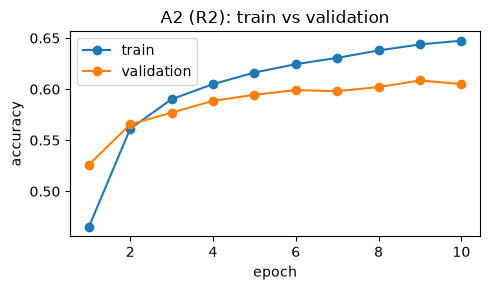

gap at the last epoch: 0.042


In [48]:
def training_curve(architecture):
    # train once on train_pairs (with R2) and return train and validation accuracy per epoch
    settings = architecture["smlp_args"]
    metrics, best_epoch, predictions = part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), R2, save_to="results/curve",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    train_accuracy = []
    val_accuracy = []
    for epoch in metrics:
        train_accuracy.append(epoch["train_metrics"]["accuracy"])
        val_accuracy.append(epoch["val_metrics"]["accuracy"])
    return train_accuracy, val_accuracy


train_acc, val_acc = training_curve(A2)

epochs = range(1, len(train_acc) + 1)
plt.figure(figsize=(5, 3))
plt.plot(epochs, train_acc, marker="o", label="train")
plt.plot(epochs, val_acc, marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("A2 (R2): train vs validation")
plt.legend()
plt.tight_layout()
plt.show()

print("gap at the last epoch:", round(train_acc[-1] - val_acc[-1], 3))

**A3** follows from what we see: A2's validation accuracy levels off while training accuracy keeps going up, so A2 overfits. With only 20k pairs and 2,000+ input numbers, the network has many more weights than there are examples.

A3 therefore uses a **smaller hidden layer (32 instead of 128)** and **stronger dropout (0.5 instead of 0.1)**. Because this makes learning slower, it trains for **30 epochs** instead of 10. The course code keeps the epoch with the best validation loss, so extra epochs cannot hurt.

In [49]:
A3 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 32, "dropout": 0.5, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 30},
}

train_acc3, val_acc3 = training_curve(A3)
print("A3 last epoch: train", round(train_acc3[-1], 3), "| validation", round(val_acc3[-1], 3),
      "| gap", round(train_acc3[-1] - val_acc3[-1], 3))

Transforming documents...
Document transformation done! Time taken: 2.238 seconds
Dataloader done! Time taken: 0.779 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0895 | train acc: 0.3837 | val loss: 1.0710 | val acc: 0.4645
Epoch 02 | train loss: 1.0517 | train acc: 0.4714 | val loss: 1.0214 | val acc: 0.5155
Epoch 03 | train loss: 1.0128 | train acc: 0.5067 | val loss: 0.9849 | val acc: 0.5430
Epoch 04 | train loss: 0.9837 | train acc: 0.5303 | val loss: 0.9592 | val acc: 0.5535
Epoch 05 | train loss: 0.9596 | train acc: 0.5493 | val loss: 0.9408 | val acc: 0.5645
Epoch 06 | train loss: 0.9430 | train acc: 0.5627 | val loss: 0.9278 | val acc: 0.5690
Epoch 07 | train loss: 0.9267 | train acc: 0.5727 | val loss: 0.9168 | val acc: 0.5775
Epoch 08 | train loss: 0.9154 | train acc: 0.5804 | val loss: 0.9098 | val acc: 0.5845
Epoch 09 | train loss: 0.9046 | train acc: 0.5865 | val loss: 0.9030 | val acc: 0.5860
Epoch 10 | train loss: 0.8963 | train acc: 0.5919 | val loss: 0.8983 | val acc: 0.5885
Epoch 11 | train loss: 0.8865 | train acc: 0.5967 | val loss: 0.8950 | val acc: 0.5885
Epoch 12 | train loss: 0.8809 | train acc: 

In [50]:
run("A3_R1", R1, A3)
run("A3_R2", R2, A3)
run("A3_R3", R3, A3)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.019 seconds
Dataloader done! Time taken: 0.488 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0969 | train acc: 0.3595 | val loss: 1.0833 | val acc: 0.4199
Epoch 02 | train loss: 1.0681 | train acc: 0.4405 | val loss: 1.0475 | val acc: 0.5004
Epoch 03 | train loss: 1.0288 | train acc: 0.4935 | val loss: 1.0099 | val acc: 0.5276
Epoch 04 | train loss: 0.9964 | train acc: 0.5193 | val loss: 0.9832 | val acc: 0.5400
Epoch 05 | train loss: 0.9716 | train acc: 0.5395 | val loss: 0.9644 | val acc: 0.5496
Epoch 06 | train loss: 0.9531 | train acc: 0.5541 | val loss: 0.9503 | val acc: 0.5573
Epoch 07 | train loss: 0.9385 | train acc: 0.5650 | val loss: 0.9398 | val acc: 0.5647
Epoch 08 | train loss: 0.9219 | train acc: 0.5747 | val loss: 0.9302 | val acc: 0.5697
Epoch 09 | train loss: 0.9117 | train acc: 0.5850 | val loss: 0.9227 | val acc: 0.5735
Epoch 10 | train loss: 0.9006 | train acc: 0.5877 | val loss: 0.9170 | val acc: 0.5768
Epoch 11 | train loss: 0.8912 | train acc: 0.5953 | val loss: 0.9121 | val acc: 0.5785
Epoch 12 | train loss: 0.8844 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0933 | train acc: 0.3731 | val loss: 1.0818 | val acc: 0.4404
Epoch 02 | train loss: 1.0655 | train acc: 0.4514 | val loss: 1.0488 | val acc: 0.5051
Epoch 03 | train loss: 1.0274 | train acc: 0.4998 | val loss: 1.0142 | val acc: 0.5252
Epoch 04 | train loss: 0.9979 | train acc: 0.5214 | val loss: 0.9913 | val acc: 0.5383
Epoch 05 | train loss: 0.9736 | train acc: 0.5406 | val loss: 0.9748 | val acc: 0.5481
Epoch 06 | train loss: 0.9548 | train acc: 0.5525 | val loss: 0.9627 | val acc: 0.5519
Epoch 07 | train loss: 0.9387 | train acc: 0.5659 | val loss: 0.9532 | val acc: 0.5561
Epoch 08 | train loss: 0.9262 | train acc: 0.5744 | val loss: 0.9455 | val acc: 0.5616
Epoch 09 | train loss: 0.9145 | train acc: 0.5840 | val loss: 0.9397 | val acc: 0.5608
Epoch 10 | train loss: 0.9022 | train acc: 0.5898 | val loss: 0.9343 | val acc: 0.5645
Epoch 11 | train loss: 0.8947 | train acc: 0.5951 | val loss: 0.9298 | val acc: 0.5649
Epoch 12 | train loss: 0.8857 | train acc: 

... (26 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0772 | train acc: 0.4311 | val loss: 1.0390 | val acc: 0.5625
Epoch 02 | train loss: 1.0038 | train acc: 0.5363 | val loss: 0.9548 | val acc: 0.6022
Epoch 03 | train loss: 0.9393 | train acc: 0.5786 | val loss: 0.8983 | val acc: 0.6226
Epoch 04 | train loss: 0.8936 | train acc: 0.6070 | val loss: 0.8607 | val acc: 0.6396
Epoch 05 | train loss: 0.8589 | train acc: 0.6262 | val loss: 0.8341 | val acc: 0.6492
Epoch 06 | train loss: 0.8334 | train acc: 0.6404 | val loss: 0.8145 | val acc: 0.6577
Epoch 07 | train loss: 0.8145 | train acc: 0.6488 | val loss: 0.8017 | val acc: 0.6620
Epoch 08 | train loss: 0.7990 | train acc: 0.6579 | val loss: 0.7901 | val acc: 0.6643
Epoch 09 | train loss: 0.7856 | train acc: 0.6673 | val loss: 0.7822 | val acc: 0.6650
Epoch 10 | train loss: 0.7740 | train acc: 0.6717 | val loss: 0.7761 | val acc: 0.6687
Epoch 11 | train loss: 0.7645 | train acc: 0.6757 | val loss: 0.7707 | val acc: 0.6691
Epoch 12 | train loss: 0.7558 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0766 | train acc: 0.4172 | val loss: 1.0344 | val acc: 0.5532
Epoch 02 | train loss: 0.9960 | train acc: 0.5432 | val loss: 0.9491 | val acc: 0.5989
Epoch 03 | train loss: 0.9314 | train acc: 0.5840 | val loss: 0.8960 | val acc: 0.6157
Epoch 04 | train loss: 0.8870 | train acc: 0.6129 | val loss: 0.8623 | val acc: 0.6263
Epoch 05 | train loss: 0.8540 | train acc: 0.6318 | val loss: 0.8385 | val acc: 0.6358
Epoch 06 | train loss: 0.8263 | train acc: 0.6446 | val loss: 0.8214 | val acc: 0.6403
Epoch 07 | train loss: 0.8093 | train acc: 0.6544 | val loss: 0.8088 | val acc: 0.6464
Epoch 08 | train loss: 0.7933 | train acc: 0.6605 | val loss: 0.7993 | val acc: 0.6514
Epoch 09 | train loss: 0.7828 | train acc: 0.6706 | val loss: 0.7919 | val acc: 0.6540
Epoch 10 | train loss: 0.7701 | train acc: 0.6736 | val loss: 0.7860 | val acc: 0.6562
Epoch 11 | train loss: 0.7590 | train acc: 0.6811 | val loss: 0.7812 | val acc: 0.6574
Epoch 12 | train loss: 0.7491 | train acc: 

## 7. Results and Bayesian analysis

First an overview of all nine systems.

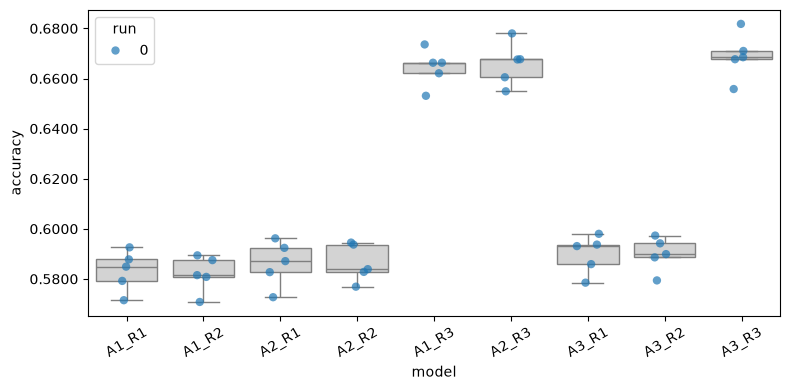

,R1,R2,R3
A1,0.5832,0.5820,0.6643
A2,0.5862,0.5864,0.6657
A3,0.5898,0.5899,0.6690


In [51]:
df_results = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df_results)

# table: mean accuracy for every architecture (rows) and representation (columns)
table = pd.DataFrame(index=["A1", "A2", "A3"], columns=["R1", "R2", "R3"], dtype=float)
for a in ["A1", "A2", "A3"]:
    for r in ["R1", "R2", "R3"]:
        name = a + "_" + r
        table.loc[a, r] = df_results[df_results["model"] == name]["accuracy"].mean()
table.round(4)

**ROPE (region of practical equivalence).** An accuracy measured on n examples has a standard error of about √(acc·(1−acc)/n). On the ~10k test pairs that is about 0.005, so a difference smaller than about 2 standard errors (**0.01**) is within the noise of the measurement itself. We call such differences *practically equivalent*. For comparison we also report the tutorial's ROPE of 0.005.

In [52]:
acc = df_results["accuracy"].mean()
n = len(test_pairs)
standard_error = np.sqrt(acc * (1 - acc) / n)
print("standard error on the test set (n =", n, "):", round(standard_error, 4))

ROPE = 0.01

standard error on the test set (n = 9824 ): 0.0049


**Comparisons, one factor at a time.** For each pair of systems A and B, `BenavoliCorrelatedT` gives a distribution over the mean accuracy difference (B − A), taking into account that cross-validation folds overlap. We report the probability that A is better, that they are practically equivalent (difference inside the ROPE), and that B is better.

1. **Representations** (architecture fixed to A1): R1 vs R2, R2 vs R3
2. **Architectures** (representation fixed to the best one from step 1): A1 vs A2, A2 vs A3
3. **Best system vs. the tutorial default** (A1_R1)

best representation with A1: R3 | best system overall: A3_R3


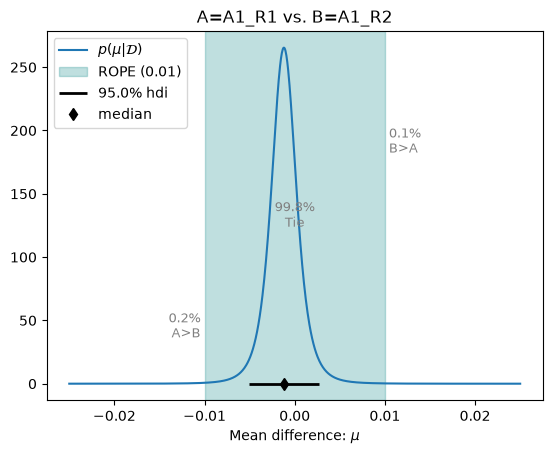

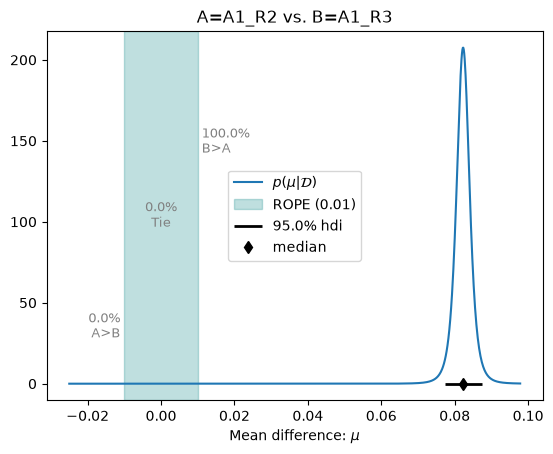

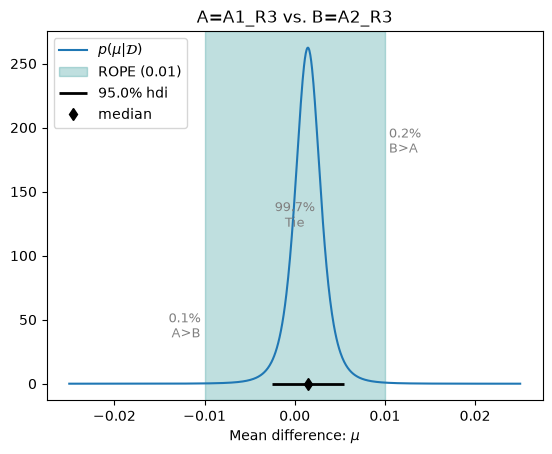

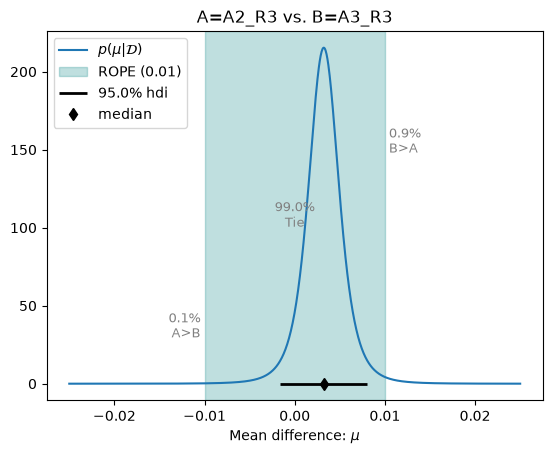

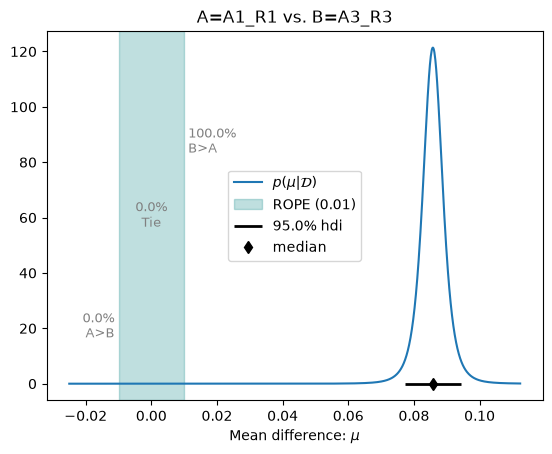

,A,B,mean diff (B-A),effect size,P(A better) 0.005,P(equivalent) 0.005,P(B better) 0.005,P(A better) 0.01,P(equivalent) 0.01,P(B better) 0.01
0,A1_R1,A1_R2,-0.001,-0.849,0.027,0.967,0.006,0.002,0.998,0.001
1,A1_R2,A1_R3,0.082,45.563,0.000,0.000,1.000,0.000,0.000,1.000
2,A1_R3,A2_R3,0.001,1.022,0.005,0.960,0.034,0.001,0.997,0.002
3,A2_R3,A3_R3,0.003,1.849,0.005,0.813,0.182,0.001,0.990,0.009
4,A1_R1,A3_R3,0.086,27.764,0.000,0.000,1.000,0.000,0.000,1.000


In [53]:
def get_accuracies(name):
    # all fold accuracies of one system, as one array
    accuracies = []
    for result in my_classifiers[name]:
        for accuracy in result["accuracies"].values():
            accuracies.append(accuracy)
    return np.array(accuracies)


def compare(a, b):
    acc_a = get_accuracies(a)
    acc_b = get_accuracies(b)

    # if the accuracies are exactly the same on every fold there is nothing to compare
    if np.allclose(acc_a, acc_b):
        print(a, "and", b, "have identical accuracies on every fold -> practically equivalent")
        return {"A": a, "B": b, "mean diff (B-A)": 0.0}

    posterior = part1.analysis.BenavoliCorrelatedT(acc_a, acc_b, runs=len(my_seeds), names=[a, b])
    row = {"A": a, "B": b, "mean diff (B-A)": posterior.mean_diff, "effect size": posterior.effect_size}

    for rope in [0.005, ROPE]:
        p_a, p_tie, p_b = posterior.probs(rope)
        row["P(A better) " + str(rope)] = p_a
        row["P(equivalent) " + str(rope)] = p_tie
        row["P(B better) " + str(rope)] = p_b

    posterior.plot(ROPE)
    plt.show()
    return row


# best representation when the architecture is A1
best_rep = "R1"
for r in ["R2", "R3"]:
    if get_accuracies("A1_" + r).mean() > get_accuracies("A1_" + best_rep).mean():
        best_rep = r

# best system overall
best_system = None
for name in my_classifiers:
    if best_system is None or get_accuracies(name).mean() > get_accuracies(best_system).mean():
        best_system = name

print("best representation with A1:", best_rep, "| best system overall:", best_system)

pairs_to_compare = [
    ("A1_R1", "A1_R2"),
    ("A1_R2", "A1_R3"),
    ("A1_" + best_rep, "A2_" + best_rep),
    ("A2_" + best_rep, "A3_" + best_rep),
]
if best_system != "A1_R1":
    pairs_to_compare.append(("A1_R1", best_system))

rows = []
for a, b in pairs_to_compare:
    rows.append(compare(a, b))
comparison = pd.DataFrame(rows)
comparison.round(3)

## 8. Test set (once)

Finally we train the best system on all 20,000 training pairs and evaluate it **once** on SNLI's test set. We report accuracy, macro-F1 and the confusion matrix, which shows which labels get confused with each other.

Transforming documents...
Document transformation done! Time taken: 2.518 seconds
Dataloader done! Time taken: 0.668 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0694 | train acc: 0.4395 | val loss: 1.0046 | val acc: 0.5760
Epoch 02 | train loss: 0.9714 | train acc: 0.5593 | val loss: 0.9002 | val acc: 0.6260
Epoch 03 | train loss: 0.9023 | train acc: 0.6004 | val loss: 0.8417 | val acc: 0.6495
Epoch 04 | train loss: 0.8591 | train acc: 0.6237 | val loss: 0.8096 | val acc: 0.6625
Epoch 05 | train loss: 0.8314 | train acc: 0.6390 | val loss: 0.7894 | val acc: 0.6750
Epoch 06 | train loss: 0.8082 | train acc: 0.6536 | val loss: 0.7716 | val acc: 0.6775
Epoch 07 | train loss: 0.7928 | train acc: 0.6593 | val loss: 0.7612 | val acc: 0.6775
Epoch 08 | train loss: 0.7781 | train acc: 0.6690 | val loss: 0.7528 | val acc: 0.6815
Epoch 09 | train loss: 0.7674 | train acc: 0.6731 | val loss: 0.7464 | val acc: 0.6830
Epoch 10 | train loss: 0.7574 | train acc: 0.6786 | val loss: 0.7403 | val acc: 0.6840
Epoch 11 | train loss: 0.7483 | train acc: 0.6850 | val loss: 0.7359 | val acc: 0.6880
Epoch 12 | train loss: 0.7417 | train acc: 

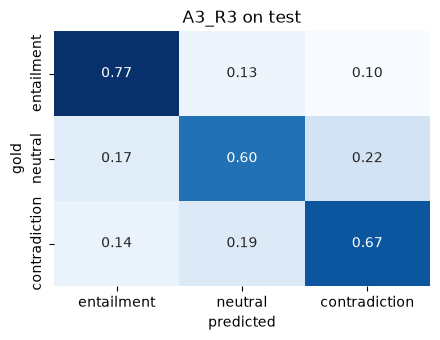

In [54]:
final = best_system
architecture_name = final.split("_")[0]
representation_name = final.split("_")[1]

if representation_name == "R1":
    encoder = R1
elif representation_name == "R2":
    encoder = R2
else:
    encoder = R3

if architecture_name == "A1":
    architecture = A1
elif architecture_name == "A2":
    architecture = A2
else:
    architecture = A3

test_texts = []
gold = []
for pair, label in test_pairs:
    test_texts.append(pair)
    gold.append(label)

if architecture["model_option"] == "logistic":
    model = part1.loglin.fit(train_pairs, encoder, max_iter=architecture["loglin_args"]["max_iter"])
    preds = part1.loglin.predict(test_texts, model, encoder)
else:
    # val_pairs is only used to pick the best epoch, the test set is only used for predicting
    settings = architecture["smlp_args"]
    part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), encoder, save_to="results/final_model",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    model = part1.smlp.load("results/final_model")
    probabilities = part1.smlp.predict_probs(test_texts, model, encoder, batch_size=256)
    preds = probabilities.argmax(axis=1)   # the label with the highest probability

print(final, "on the test set: accuracy", round(accuracy_score(gold, preds), 4),
      "| macro-F1", round(f1_score(gold, preds, average="macro"), 4))
print(classification_report(gold, preds, target_names=list(LABELS)))

cm = confusion_matrix(gold, preds, normalize="true")
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=list(LABELS), yticklabels=list(LABELS))
plt.xlabel("predicted")
plt.ylabel("gold")
plt.title(final + " on test")
plt.tight_layout()
plt.show()

## Conclusions

**Data**
- The labels are balanced (contradiction 34.0%, neutral 33.2%, entailment 32.9%), so **accuracy is a fair metric**. The majority baseline is **0.340**.
- Premises have the same length for every label (~12.9 words), but hypotheses differ: entailment is shortest (6.7 words), neutral longest (8.2 words). Negation occurs about 6× more often in contradiction hypotheses (4.9%) than in the others (<1%), but is rare overall.

**Tokenizer**
- With a vocabulary of 1,000, frequent words stay whole (`▁man`, `▁holding`) but rarer words are split into many small pieces (`introduces` → `▁in t ro d u c es`). A larger vocabulary might give more informative tokens.

**Representations** (all comparisons with ROPE = 0.01)
- **R1 vs R2:** 0.552 vs 0.550, P(equivalent) = 0.998 → **practically equivalent**. This is expected: in short sentences almost every token occurs only once, so counts (R2) and indicators (R1) are nearly the same vector.
- **R2 vs R3:** 0.550 → 0.626 (+0.075), P(R3 better) = 1.00 → **by far the largest effect in the project**. Features that describe the relation between premise and hypothesis help a lot.
- The gain from R3 is about the same for all three architectures (A1 +0.075, A2 +0.080, A3 +0.080). So the MLPs do **not** learn these relations by themselves from R1/R2; they need them as explicit features.

**Architectures** (on R3)
- **A1 vs A2:** 0.626 → 0.637 (+0.012), P(A2 better) = 0.74, P(equivalent) = 0.26 → the MLP is **probably slightly better**, but the difference is close to the ROPE.
- **A2 vs A3:** 0.637 → 0.640 (+0.002), P(equivalent) = 0.997 → **practically equivalent**. A2 overfits (train 0.656 vs validation 0.577 at epoch 10, gap +0.079), but the extra regularisation in A3 only reduced the gap a little (+0.070) and did not improve accuracy.
- With R1 and R2, the MLPs are only marginally better than the log-linear model (+0.005 to +0.009).

**Best system**
- **A3_R3**: CV accuracy **0.640**, test accuracy **0.654**, macro-F1 **0.650**. Compared to the tutorial default A1_R1 (0.552): +0.088, P(better) = 1.00.
- A2_R3 and A3_R3 are practically equivalent, and A1_R3 is close. In practice, **A1_R3 could be a sensible choice** too: it trains in seconds instead of minutes and its weights can be inspected.
- The test accuracy is a bit higher than the CV accuracy, probably because the final model is trained on all 20k pairs instead of 16k per fold.

**Confusion matrix**
- **Entailment** is recognised best (recall 0.76). **Neutral** is the hardest (recall 0.57): it is confused with both entailment (20%) and contradiction (23%). Contradiction is often predicted as neutral (21%).
- This makes sense: *neutral* means the hypothesis adds information that is not in the premise, and with bag-of-words features (no word order, no meaning) that is hard to detect.

**Limitations**
- Only 20k of ~550k training pairs, one random sample and one seed (5 measurements per system).
- Bag-of-words ignores word order ("man bites dog" = "dog bites man").
- The folds are split randomly by pair, so the same premise can appear in training and validation.
- For the MLPs, the course code reports each fold's accuracy at the epoch with the best loss on that same fold, which slightly favours the MLPs.
- The best system was chosen on the CV results; A3 was designed after looking at A2 on a separate validation set.